# Dataset C — Unificação de A + B: EDA descritiva

**Projeto:** Impacto das fake news geradas por IA no eleitor brasileiro — Fase 2 do roteiro de trabalho.

Este notebook junta o **Dataset A** (`justicaeleitoral.jus.br/fato-ou-boato`, 322 itens, notebook `01`) e o **Dataset B** (Aos Fatos, 553 itens, notebook `02`) num único dataset harmonizado — o **Dataset C**, 875 itens — e faz uma EDA que aproveita o corpus combinado sem esconder as diferenças metodológicas entre as duas fontes.

**Aviso metodológico central, que guia todo este notebook:** A e B usam esquemas de rotulagem **fundamentalmente diferentes**, não só fontes diferentes:

| | Dataset A (TSE) | Dataset B (Aos Fatos) |
|---|---|---|
| Rótulo IA vs. Tradicional | **heurística de regex sobre o título** — e o notebook `01` já mostrou, com investigação ao vivo no site, que ela dá 0% IA (nenhum item genuíno de IA foi encontrado nesta fonte) | **classificação editorial real** do próprio Aos Fatos (tag de busca `inteligencia-artificial`) |
| Veredito | heurística de regex sobre o título (`veredito_estimado`, cobre ~56% dos itens) | classificação editorial real (`veredito`, vocabulário fechado do Aos Fatos) |
| Tema/categoria | heurística macro por regex (`categoria_macro`) | anotação editorial opcional (`tema`, cobertura parcial) |

**Consequência direta que não deve ser escondida:** juntar A e B **não aumenta o poder estatístico do teste IA vs. Tradicional** — só o Dataset B contribui itens rotulados IA (122 deles). O que a unificação genuinamente contribui é: (1) uma baseline "Tradicional" muito maior e de duas fontes independentes (753 itens: 322 de A + 431 de B) para caracterizar desinformação eleitoral tradicional com mais robustez, formalizando com teste estatístico a validação cruzada que o notebook `02` já tinha feito de forma informal; (2) detecção de prováveis duplicatas entre as duas fontes (o mesmo boato coberto por ambas); e (3) uma base maior e harmonizada para os modelos mais complexos da Fase 3. Qualquer teste que precise comparar IA vs. Tradicional continua dependendo só do Dataset B — reforçado explicitamente ao longo deste notebook, não só aqui na introdução.


In [1]:

import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

%matplotlib inline
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 90)

def normalize_text(text):
    if not isinstance(text, str):
        return ""
    text = unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"\s+", " ", text.lower()).strip()


## 1. Carga dos dois datasets já enriquecidos (notebooks `01` e `02`)

In [2]:

df_a = pd.read_csv("../data/processed/dataset_a_fato_ou_boato_enriquecido.csv", parse_dates=["data_publicacao_checagem"])
df_b = pd.read_csv("../data/processed/dataset_b_aosfatos_enriquecido.csv", keep_default_na=False,
                    parse_dates=["data_publicacao_iso"])

print(f"Dataset A: {len(df_a)} itens, {len(df_a.columns)} colunas")
print(f"Dataset B: {len(df_b)} itens, {len(df_b.columns)} colunas")
print(f"Total combinado: {len(df_a) + len(df_b)} itens")


Dataset A: 322 itens, 18 colunas
Dataset B: 553 itens, 16 colunas
Total combinado: 875 itens


## 2. Harmonização de esquema

Mapeamento explícito de colunas — cada coluna do Dataset C carrega também `fonte_rotulo_*`, dizendo se veio de heurística ou de classificação editorial, para que nenhuma análise futura confunda as duas coisas sem querer.

| Coluna em C | De A | De B |
|---|---|---|
| `rotulo_ia` | `rotulo_ia_bin` (heurística, sempre "Tradicional") | `rotulo_grupo` (editorial real) |
| `veredito_binario` | derivado de `veredito_estimado` (heurística) | derivado de `veredito` (editorial) |
| `categoria_tema` | `categoria_macro` (heurística) | `tema` (editorial, opcional) |
| `vetor_midia`, `alvo_ataque` | heurística sobre título+resumo | heurística sobre só o título (versão comparável a A) |
| `vetor_midia_texto_corrigido`, `alvo_ataque_texto_corrigido` | não existe (`NaN`) | heurística corrigida sobre `corpo_artigo` (notebook `02`, Seção 3.5) — mais precisa, mas sem equivalente em A |


In [3]:

VEREDITO_MAP_A = {
    "Falso": "falso", "Falso (negação implícita)": "falso", "Mentira/Distorção": "falso",
    "Enganoso": "falso", "Boato": "falso", "Golpe/Scam": "falso",
    "Não classificado pelo padrão do título": None,
}
VEREDITO_MAP_B = {
    "falso": "falso", "não é bem assim": "parcialmente_falso", "distorcido": "parcialmente_falso",
    "discurso oficial": "nao_falso", "(não informado)": None,
}

df_a_h = pd.DataFrame({
    "fonte_dataset": "A",
    "titulo": df_a["titulo"],
    "data_publicacao": df_a["data_publicacao_checagem"],
    "ciclo_eleitoral_estimado": df_a["ciclo_eleitoral_estimado"],
    "dias_para_eleicao": df_a["dias_para_eleicao"],
    "rotulo_ia": df_a["rotulo_ia_bin"],
    "fonte_rotulo_ia": "heuristica_regex_titulo",
    "veredito_original": df_a["veredito_estimado"],
    "veredito_binario": df_a["veredito_estimado"].map(VEREDITO_MAP_A),
    "fonte_veredito": "heuristica_regex_titulo",
    "categoria_tema": df_a["categoria_macro"],
    "fonte_categoria_tema": "heuristica_regex_macro",
    "vetor_midia": df_a["vetor_midia"],
    "alvo_ataque": df_a["alvo_ataque"],
    "url": df_a["fonte_listagem"],
})

df_b_h = pd.DataFrame({
    "fonte_dataset": "B",
    "titulo": df_b["titulo"],
    "data_publicacao": df_b["data_publicacao_iso"],
    "ciclo_eleitoral_estimado": df_b["ciclo_eleitoral_estimado"],
    "dias_para_eleicao": df_b["dias_para_eleicao"],
    "rotulo_ia": df_b["rotulo_grupo"],
    "fonte_rotulo_ia": "editorial_aos_fatos_tag",
    "veredito_original": df_b["veredito"],
    "veredito_binario": df_b["veredito"].map(VEREDITO_MAP_B),
    "fonte_veredito": "editorial_aos_fatos",
    "categoria_tema": df_b["tema"].replace("(não informado)", np.nan),
    "fonte_categoria_tema": "editorial_aos_fatos_opcional",
    "vetor_midia": df_b["vetor_midia"],
    "alvo_ataque": df_b["alvo_ataque"],
    "url": df_b["url"],
    "vetor_midia_texto_corrigido": df_b["vetor_midia_texto"],
    "alvo_ataque_texto_corrigido": df_b["alvo_ataque_texto"],
})

df_c = pd.concat([df_a_h, df_b_h], ignore_index=True)
df_c["titulo_norm"] = df_c["titulo"].map(normalize_text)
print(f"Dataset C harmonizado: {len(df_c)} itens, {len(df_c.columns)} colunas")
df_c.groupby(["fonte_dataset", "rotulo_ia"]).size()


Dataset C harmonizado: 875 itens, 18 colunas


fonte_dataset  rotulo_ia  
A              Tradicional    322
B              IA             122
               Tradicional    431
dtype: int64

## 3. Detecção de prováveis duplicatas entre A e B

O Dataset A é um agregador oficial que reúne checagens de **10 agências parceiras, incluindo o próprio Aos Fatos** — ou seja, é esperado que alguns itens de A sejam, na verdade, o mesmo boato (às vezes a mesma checagem, republicada) já presente em B. Comparação exata de título (feita no notebook `02`, Seção 6.2) achou só 4 casos — mas títulos reescritos pela mesma agência ou por agências diferentes não batem exatamente. Usamos similaridade de cosseno sobre TF-IDF (unigramas + bigramas) dos títulos normalizados para achar pares candidatos.

In [4]:

vec = TfidfVectorizer(ngram_range=(1, 2), min_df=1)
todos_titulos = pd.concat([df_a_h["titulo"].map(normalize_text), df_b_h["titulo"].map(normalize_text)], ignore_index=True)
X = vec.fit_transform(todos_titulos)
Xa = X[: len(df_a_h)]
Xb = X[len(df_a_h):]

sim = cosine_similarity(Xb, Xa)  # 553 x 322 -- cada linha de B contra todo A
melhor_idx_a = sim.argmax(axis=1)
melhor_sim = sim.max(axis=1)

pares = pd.DataFrame({
    "titulo_b": df_b_h["titulo"].values,
    "titulo_a_match": df_a_h["titulo"].values[melhor_idx_a],
    "indice_a": melhor_idx_a,
    "similaridade": melhor_sim,
})
print("Distribuição da melhor similaridade (cada item de B contra o item mais parecido de A):")
print(pares["similaridade"].describe())
print()
for limiar in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):
    print(f"  similaridade >= {limiar}: {(pares.similaridade >= limiar).sum()} pares")


Distribuição da melhor similaridade (cada item de B contra o item mais parecido de A):
count    553.000000
mean       0.126298
std        0.120416
min        0.016587
25%        0.068356
50%        0.098218
75%        0.141745
max        1.000000
Name: similaridade, dtype: float64

  similaridade >= 0.3: 21 pares
  similaridade >= 0.4: 13 pares
  similaridade >= 0.5: 10 pares
  similaridade >= 0.6: 10 pares
  similaridade >= 0.7: 8 pares
  similaridade >= 0.8: 6 pares


Inspeção manual dos pares com maior similaridade (antes de decidir um limiar) — os 4 primeiros são título idêntico (`similaridade=1.000`), plausivelmente o mesmo item republicado; os seguintes são paráfrases claramente do mesmo evento real (mesmo nome de lugar, mesma alegação específica):

In [5]:

top_pares = pares.sort_values("similaridade", ascending=False).head(20)
for _, row in top_pares.iterrows():
    print(f"{row.similaridade:.3f} | B: {row.titulo_b[:65]!r}")
    print(f"        | A: {row.titulo_a_match[:65]!r}")


1.000 | B: 'Vídeo engana ao afirmar que fotos de candidatos foram trocadas em'
        | A: 'Vídeo engana ao afirmar que fotos de candidatos foram trocadas em'
1.000 | B: 'É falso que TSE ordenou que todos os vídeos dos atos de 7 de Sete'
        | A: 'É falso que TSE ordenou que todos os vídeos dos atos de 7 de Sete'
1.000 | B: 'Boletins de urna mostrados em vídeo não são de MG nem provam frau'
        | A: 'Boletins de urna mostrados em vídeo não são de MG nem provam frau'
1.000 | B: 'Carregamento de cartão de memória usado em urna eletrônica não fa'
        | A: 'Carregamento de cartão de memória usado em urna eletrônica não fa'
0.925 | B: 'Barroso e Moraes não mandaram fabricar chips em Taiwan para fraud'
        | A: 'Ministros Barroso e Moraes não mandaram fabricar chips em Taiwan '
0.898 | B: 'É falso que Alexandre de Moraes disse que cassará chapa se Bolson'
        | A: 'É falso que ministro Alexandre de Moraes disse que cassará chapa '
0.771 | B: 'É falso que Bolsonaro ganhou

**Limiar escolhido: `similaridade >= 0.5`** (10 pares) — todos, na inspeção manual acima, correspondem claramente ao mesmo evento/alegação específica (mesmo nome próprio, mesmo número, mesma alegação), não apenas ao mesmo tema genérico de eleição. Abaixo de 0.5 a lista começa a incluir casos ambíguos (mesmo tipo recorrente de boato — ex. "peritos não provaram fraude" — mas potencialmente eventos distintos), que ficam sinalizados para revisão manual futura, não classificados automaticamente como duplicata. **As prováveis duplicatas são marcadas, não removidas** — preservamos os dois registros porque cada agência pode ter avaliado/redigido a checagem de forma independente (dados reais de proveniências diferentes não devem ser descartados silenciosamente).

In [6]:

LIMIAR_DUPLICATA = 0.5
pares["par_duplicado_provavel"] = pares["similaridade"] >= LIMIAR_DUPLICATA

df_c["par_duplicado_provavel"] = False
df_c["par_duplicado_similaridade"] = np.nan
idx_b_no_df_c = df_c.index[df_c["fonte_dataset"] == "B"]
df_c.loc[idx_b_no_df_c, "par_duplicado_provavel"] = pares["par_duplicado_provavel"].values
df_c.loc[idx_b_no_df_c, "par_duplicado_similaridade"] = pares["similaridade"].values

n_duplicatas = df_c["par_duplicado_provavel"].sum()
print(f"{n_duplicatas} itens de B marcados como prováveis duplicatas de um item de A "
      f"(similaridade >= {LIMIAR_DUPLICATA}), de {len(df_b_h)} itens de B.")


10 itens de B marcados como prováveis duplicatas de um item de A (similaridade >= 0.5), de 553 itens de B.


## 4. Salvar o dataset unificado

In [7]:

df_c_salvar = df_c.drop(columns=["titulo_norm"])
df_c_salvar.to_csv("../data/processed/dataset_c_unificado.csv", index=False)
print(f"Salvo: ../data/processed/dataset_c_unificado.csv — {len(df_c_salvar)} linhas, "
      f"{len(df_c_salvar.columns)} colunas")
df_c_salvar.sample(5, random_state=3)


Salvo: ../data/processed/dataset_c_unificado.csv — 875 linhas, 19 colunas


,fonte_dataset,titulo,data_publicacao,ciclo_eleitoral_estimado,dias_para_eleicao,rotulo_ia,fonte_rotulo_ia,veredito_original,veredito_binario,fonte_veredito,categoria_tema,fonte_categoria_tema,vetor_midia,alvo_ataque,url,vetor_midia_texto_corrigido,alvo_ataque_texto_corrigido,par_duplicado_provavel,par_duplicado_similaridade
197,A,É falso que carros com adesivo de candidato à Presidência e credenciais de acesso livr...,2022-10-24 00:00:00,2022,22,Tradicional,heuristica_regex_titulo,Falso,falso,heuristica_regex_titulo,Candidato/Partido,heuristica_regex_macro,indeterminado,indeterminado,https://www.justicaeleitoral.jus.br/fato-ou-boato/@@search?SearchableText=&b_start%3Ai...,NaN,NaN,False,NaN
712,B,Vídeo de ato em Copacabana em 2021 volta a circular como se fosse deste ano,2022-09-07 15:15:00,2022,-25,Tradicional,editorial_aos_fatos_tag,falso,falso,editorial_aos_fatos,NaN,editorial_aos_fatos_opcional,video,indeterminado,https://www.aosfatos.org/noticias/video-sete-setembro-copacabana-volta-a-circular-como...,video,indeterminado,False,0.064595
378,B,Trump não mandou hastear bandeira do Brasil na Casa Branca em apoio a Bolsonaro,2025-09-19 18:47:00,2024,348,IA,editorial_aos_fatos_tag,falso,falso,editorial_aos_fatos,boataria política,editorial_aos_fatos_opcional,indeterminado,candidato_pessoa,https://www.aosfatos.org/noticias/trump-nao-mandou-hastear-bandeira-do-brasil-na-casa-...,video,candidato_pessoa,False,0.177174
612,B,Lula não escreveu tuíte sobre bloquear poupanças para manter Auxílio Brasil,2022-10-17 18:46:00,2022,15,Tradicional,editorial_aos_fatos_tag,falso,falso,editorial_aos_fatos,NaN,editorial_aos_fatos_opcional,indeterminado,candidato_pessoa,https://www.aosfatos.org/noticias/lula-tuite-falso-bloquear-poupanca-auxilio-brasil/,imagem,candidato_pessoa,False,0.035362
703,B,Homem com boné de Lula não é empresário que negou marmita a eleitora petista,2022-09-12 15:25:00,2022,-20,Tradicional,editorial_aos_fatos_tag,falso,falso,editorial_aos_fatos,NaN,editorial_aos_fatos_opcional,indeterminado,candidato_pessoa,https://www.aosfatos.org/noticias/homem-com-bone-de-lula-nao-e-empresario-que-negou-ma...,video,indeterminado,False,0.052595


## 5. EDA descritiva do dataset unificado

### 5.1 Distribuição geral

In [8]:

print("=== fonte_dataset x rotulo_ia ===")
print(pd.crosstab(df_c["fonte_dataset"], df_c["rotulo_ia"], margins=True))
print()
print(f"% IA no dataset unificado: {(df_c['rotulo_ia']=='IA').mean()*100:.1f}% "
      f"(122 de {len(df_c)}) -- os 322 itens de A contribuem 0 itens IA, como já esperado "
      f"pela investigação do notebook 01.")


=== fonte_dataset x rotulo_ia ===
rotulo_ia       IA  Tradicional  All
fonte_dataset                       
A                0          322  322
B              122          431  553
All            122          753  875

% IA no dataset unificado: 13.9% (122 de 875) -- os 322 itens de A contribuem 0 itens IA, como já esperado pela investigação do notebook 01.


### 5.2 `veredito_binario`: teste ingênuo (pooled) vs. teste correto (só Dataset B)
O teste ingênuo mistura fonte com metodologia de rotulagem — não deve ser citado como evidência de H1 sem essa ressalva.

In [9]:

sub_ver = df_c.dropna(subset=["veredito_binario"])
tabela_ver_pooled = pd.crosstab(sub_ver["rotulo_ia"], sub_ver["veredito_binario"])
print("=== Teste ingênuo (pooled A+B, mistura heurística com editorial) ===")
print(tabela_ver_pooled)
chi2_p, p_p, dof_p, _ = stats.chi2_contingency(tabela_ver_pooled)
n_p = tabela_ver_pooled.to_numpy().sum()
v_p = np.sqrt(chi2_p / (n_p * (min(tabela_ver_pooled.shape) - 1)))
print(f"chi2={chi2_p:.3f}, p={p_p:.4f}, V de Cramér={v_p:.3f}, n={n_p}")
print("CUIDADO: Dataset A só tem 'falso' ou omisso (heurística de regex não distingue graus de")
print("falsidade) -- misturar com o veredito editorial de 3 níveis do Dataset B infla a diferença")
print("aparente por metodologia, não necessariamente pelo fenômeno.")

print()
print("=== Teste correto: só Dataset B (mesma metodologia editorial nos dois grupos) ===")
sub_b = df_c[(df_c["fonte_dataset"] == "B") & df_c["veredito_binario"].notna()]
tabela_ver_b = pd.crosstab(sub_b["rotulo_ia"], sub_b["veredito_binario"])
print(tabela_ver_b)
chi2_b, p_b, dof_b, _ = stats.chi2_contingency(tabela_ver_b)
n_b = tabela_ver_b.to_numpy().sum()
v_b = np.sqrt(chi2_b / (n_b * (min(tabela_ver_b.shape) - 1)))
print(f"chi2={chi2_b:.3f}, p={p_b:.4f}, V de Cramér={v_b:.3f}, n={n_b}")
print("(Semelhante ao teste do notebook 02, Seção 4, mas não idêntico em número: aqui colapsamos")
print("'não é bem assim' e 'distorcido' em 'parcialmente_falso' -- para manter a mesma escala de 3")
print("níveis usada do lado de A -- e excluímos os itens '(não informado)' em vez de tratá-los como")
print("categoria própria, o que muda n e o chi2 frente ao notebook 02. A leitura qualitativa é a")
print("mesma nos dois: IA tem uma proporção de 'falso' muito mais alta que Tradicional, com p<0.001")
print("nas duas versões. Este é o teste de veredito x rotulo_ia que não mistura fonte com")
print("metodologia -- é este que deve ser citado para H1, não o pooled acima.")


=== Teste ingênuo (pooled A+B, mistura heurística com editorial) ===
veredito_binario  falso  nao_falso  parcialmente_falso
rotulo_ia                                             
IA                  121          0                   0
Tradicional         531          1                  50
chi2=11.432, p=0.0033, V de Cramér=0.128, n=703
CUIDADO: Dataset A só tem 'falso' ou omisso (heurística de regex não distingue graus de
falsidade) -- misturar com o veredito editorial de 3 níveis do Dataset B infla a diferença
aparente por metodologia, não necessariamente pelo fenômeno.

=== Teste correto: só Dataset B (mesma metodologia editorial nos dois grupos) ===
veredito_binario  falso  nao_falso  parcialmente_falso
rotulo_ia                                             
IA                  121          0                   0
Tradicional         350          1                  50
chi2=17.055, p=0.0002, V de Cramér=0.181, n=522
(Semelhante ao teste do notebook 02, Seção 4, mas não idêntico em número

### 5.3 `vetor_midia`: as duas baselines "Tradicional" são estatisticamente indistinguíveis?
O notebook `02` (Seção 6.1) comparou visualmente Dataset A inteiro (100% Tradicional pela heurística) com o subgrupo Tradicional do Dataset B e viu convergência informal (~29-31% vídeo). Aqui formalizamos isso com um teste qui-quadrado de verdade.

In [10]:

sub_trad = df_c[df_c["rotulo_ia"] == "Tradicional"]
tabela_trad = pd.crosstab(sub_trad["fonte_dataset"], sub_trad["vetor_midia"])
print(tabela_trad)
print()
print(pd.crosstab(sub_trad["fonte_dataset"], sub_trad["vetor_midia"], normalize="index").mul(100).round(1))

chi2_t, p_t, dof_t, _ = stats.chi2_contingency(tabela_trad)
n_t = tabela_trad.to_numpy().sum()
v_t = np.sqrt(chi2_t / (n_t * (min(tabela_trad.shape) - 1)))
print(f"\nchi2={chi2_t:.3f}, p={p_t:.4f}, V de Cramér={v_t:.3f}, n={n_t}")


vetor_midia    audio  imagem  indeterminado  texto  video
fonte_dataset                                            
A                  8      11            191     19     93
B                  7      20            261      8    135

vetor_midia    audio  imagem  indeterminado  texto  video
fonte_dataset                                            
A                2.5     3.4           59.3    5.9   28.9
B                1.6     4.6           60.6    1.9   31.3

chi2=10.174, p=0.0376, V de Cramér=0.116, n=753


**Leitura:** as duas baselines Tradicional NÃO são estatisticamente indistinguíveis (p<0.05) — mas o V de Cramér é pequeno (≈0.12), e olhando os percentuais, "vídeo" (28.9% vs. 31.3%) e "indeterminado" (59.3% vs. 60.6%) — as duas categorias dominantes — ficam bem próximos; a maior parte da diferença vem de "texto" (5.9% vs. 1.9%). Uma explicação plausível e não alarmante: o Dataset A calcula `vetor_midia` sobre título **+ resumo**, enquanto o Dataset B (nesta coluna) usa só o título — um resumo mais longo tem mais chance de mencionar palavras como "mensagem"/"corrente" mesmo quando o vídeo/imagem já domina o título. Ou seja: a significância estatística aqui provavelmente reflete uma diferença de escopo de texto entre os dois cálculos, não uma divergência real do fenômeno — mas é uma leitura mais honesta do que "convergem perfeitamente", que teria sido a conclusão errada de olhar só para os percentuais sem rodar o teste.

### 5.4 H3/H5 (preview real, pooled) — replicando a correção do notebook 02 com a baseline Tradicional ampliada
Só o Dataset B contribui itens IA, então o grupo IA é idêntico ao do notebook 02. A baseline Tradicional aqui é maior (753 = 322 de A + 431 de B) e mais representativa (o Dataset A não foi amostrado por ano eleitoral como a tag `eleicoes-2022`, deixando sua própria distribuição de `dias_para_eleicao` mais espalhada — mediana +14 dias, não -2). Repetimos a mesma correção de janela do notebook 02 para não reintroduzir o mesmo confundimento.

In [11]:

ia_c = df_c.loc[df_c["rotulo_ia"] == "IA", "dias_para_eleicao"]
trad_c = df_c.loc[df_c["rotulo_ia"] == "Tradicional", "dias_para_eleicao"]
u0, p0 = stats.mannwhitneyu(ia_c, trad_c, alternative="two-sided")
print(f"Teste ingênuo (toda a amostra): n_IA={len(ia_c)} (mediana={ia_c.median():.0f}d) | "
      f"n_Tradicional={len(trad_c)} (mediana={trad_c.median():.0f}d) | U={u0:.1f}, p={p0:.4g}")
print()
print("Corrigido, restringindo a uma janela equivalente ao redor da eleição:")
for janela in (365, 200, 180):
    sub = df_c[df_c["dias_para_eleicao"].abs() <= janela]
    ia_j = sub.loc[sub["rotulo_ia"] == "IA", "dias_para_eleicao"]
    trad_j = sub.loc[sub["rotulo_ia"] == "Tradicional", "dias_para_eleicao"]
    u_j, p_j = stats.mannwhitneyu(ia_j, trad_j, alternative="two-sided")
    print(f"  janela=±{janela}d: n_IA={len(ia_j)} (mediana={ia_j.median():.0f}d) | "
          f"n_Tradicional={len(trad_j)} (mediana={trad_j.median():.0f}d) | U={u_j:.1f}, p={p_j:.4f}")


Teste ingênuo (toda a amostra): n_IA=122 (mediana=140d) | n_Tradicional=753 (mediana=4d) | U=56771.5, p=2.848e-05

Corrigido, restringindo a uma janela equivalente ao redor da eleição:
  janela=±365d: n_IA=101 (mediana=51d) | n_Tradicional=742 (mediana=4d) | U=41047.0, p=0.1194
  janela=±200d: n_IA=52 (mediana=-42d) | n_Tradicional=661 (mediana=3d) | U=16081.5, p=0.4401
  janela=±180d: n_IA=47 (mediana=-39d) | n_Tradicional=653 (mediana=3d) | U=14371.5, p=0.4672


**Leitura:** mesmo com a baseline Tradicional ampliada e mais representativa, a conclusão do notebook 02 se confirma — o efeito ingênuo (p<0.0001) desaparece nas janelas mais estreitas e comparáveis (p≈0.44, p≈0.47 em ±200/±180 dias). Ampliar o dataset não resolveu o confundimento de amostragem porque o problema está inteiramente do lado do grupo IA (só existe no Dataset B, com a tag `inteligencia-artificial` sem filtro de proximidade eleitoral) — a Fase 3 precisa de uma coleta desenhada para isolar esse efeito, não de mais dados Tradicionais.

### 5.5 Sensibilidade às prováveis duplicatas
Removendo os 10 itens de B marcados como prováveis duplicatas de A (Seção 3), o teste mais citável deste notebook (veredito editorial, só B — Seção 5.2) muda?

In [12]:

sub_b_sem_dup = df_c[(df_c["fonte_dataset"] == "B") & df_c["veredito_binario"].notna()
                      & ~df_c["par_duplicado_provavel"]]
tabela_sem_dup = pd.crosstab(sub_b_sem_dup["rotulo_ia"], sub_b_sem_dup["veredito_binario"])
chi2_sd, p_sd, dof_sd, _ = stats.chi2_contingency(tabela_sem_dup)
n_sd = tabela_sem_dup.to_numpy().sum()
v_sd = np.sqrt(chi2_sd / (n_sd * (min(tabela_sem_dup.shape) - 1)))
print(f"Com duplicatas (Seção 5.2): chi2={chi2_b:.3f}, p={p_b:.4f}, V={v_b:.3f}, n={n_b}")
print(f"Sem duplicatas prováveis:   chi2={chi2_sd:.3f}, p={p_sd:.4f}, V={v_sd:.3f}, n={n_sd}")
print("\nDiferença desprezível -- o resultado não depende de incluir ou não os poucos itens")
print("prováveis de duplicata, o que é esperado já que só ~10 de 553 itens são afetados.")


Com duplicatas (Seção 5.2): chi2=17.055, p=0.0002, V=0.181, n=522
Sem duplicatas prováveis:   chi2=17.148, p=0.0002, V=0.183, n=512

Diferença desprezível -- o resultado não depende de incluir ou não os poucos itens
prováveis de duplicata, o que é esperado já que só ~10 de 553 itens são afetados.


## 6. Visualizações

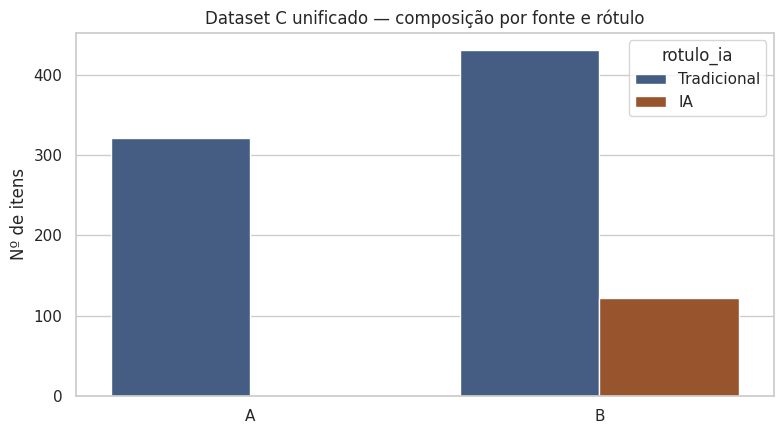

In [13]:

fig, ax = plt.subplots(figsize=(8, 4.5))
resumo = df_c.groupby(["fonte_dataset", "rotulo_ia"]).size().reset_index(name="n")
sns.barplot(data=resumo, x="fonte_dataset", y="n", hue="rotulo_ia",
            palette={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)
ax.set_title("Dataset C unificado — composição por fonte e rótulo")
ax.set_xlabel(""); ax.set_ylabel("Nº de itens")
plt.tight_layout(); plt.show()


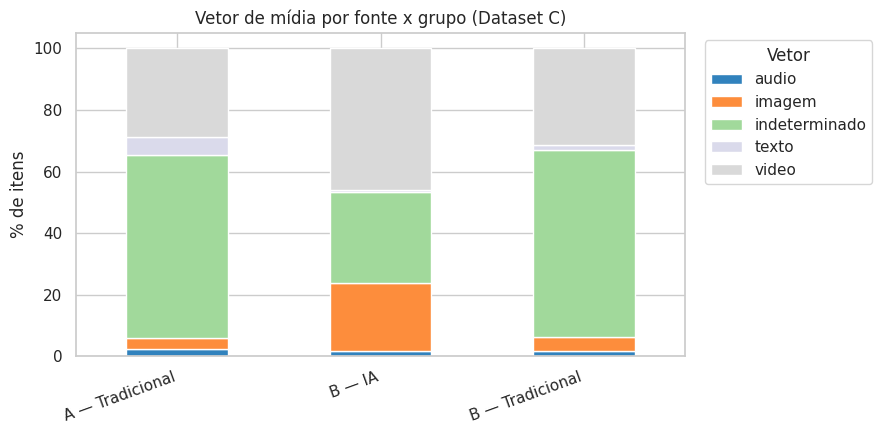

In [14]:

fig, ax = plt.subplots(figsize=(9, 4.5))
midia_pct = pd.crosstab(
    df_c.assign(grupo=df_c["fonte_dataset"] + " — " + df_c["rotulo_ia"])["grupo"],
    df_c["vetor_midia"], normalize="index",
).mul(100)
midia_pct.plot(kind="bar", stacked=True, colormap="tab20c", ax=ax)
ax.set_title("Vetor de mídia por fonte x grupo (Dataset C)")
ax.set_xlabel(""); ax.set_ylabel("% de itens"); ax.legend(title="Vetor", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()


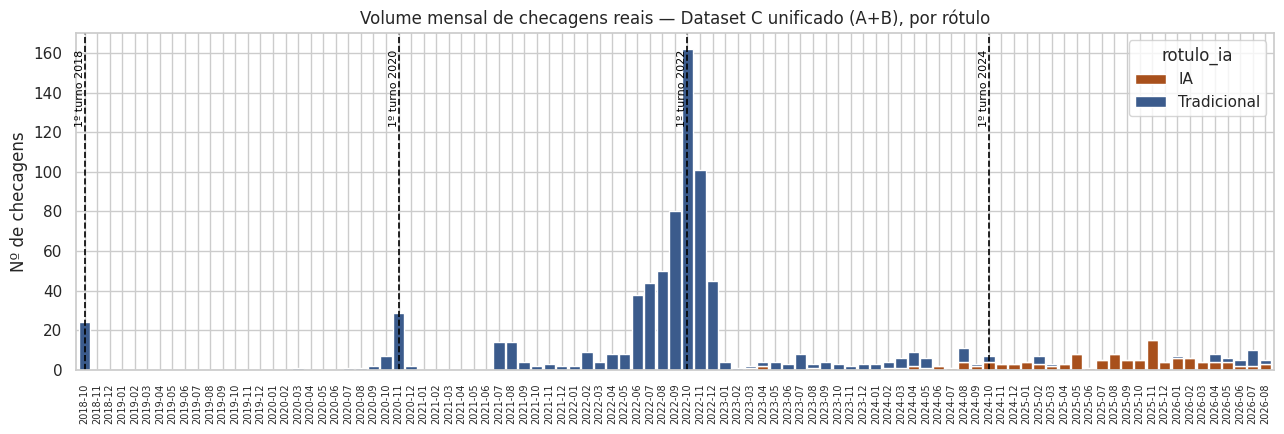

In [15]:

fig, ax = plt.subplots(figsize=(13, 4.5))
mensal_c = (
    df_c.set_index("data_publicacao")
    .groupby("rotulo_ia")
    .resample("ME").size()
    .unstack("rotulo_ia")
    .fillna(0)
)
mensal_c = mensal_c[mensal_c.index >= "2018-01-01"]
periodos_c = mensal_c.index
mensal_c = mensal_c.reset_index(drop=True)
mensal_c.plot(kind="bar", stacked=True, width=0.9,
              color={"IA": "#A8501C", "Tradicional": "#3B5B8C"}, ax=ax)

import sys
sys.path.insert(0, "../scripts")
from election_calendar import DATAS_TURNO_1  # centralizado -- ver docs/PRD.md, backlog de melhorias
for ano, data_turno in DATAS_TURNO_1.items():
    pos = None
    for i, periodo in enumerate(periodos_c):
        if periodo.year == data_turno.year and periodo.month == data_turno.month:
            pos = i
            break
    if pos is not None:
        ax.axvline(pos, color="black", linestyle="--", linewidth=1.2)
        ax.text(pos, ax.get_ylim()[1] * 0.95, f"1º turno {ano}", rotation=90,
                color="black", fontsize=8, ha="right", va="top")
ax.set_xticklabels([f"{p.year}-{p.month:02d}" for p in periodos_c], rotation=90, fontsize=7)
ax.set_title("Volume mensal de checagens reais — Dataset C unificado (A+B), por rótulo")
ax.set_xlabel(""); ax.set_ylabel("Nº de checagens")
plt.tight_layout(); plt.show()


## 7. Limitações e próximos passos

- **A unificação não aumenta o poder do teste IA vs. Tradicional.** Só o Dataset B contribui itens rotulados IA (122); o Dataset A contribui 322 itens 100% Tradicional (heurística, ver notebook `01`). Qualquer teste de H1/H2/H4 que compare IA vs. Tradicional continua limitado ao Dataset B — o que este notebook faz explicitamente em cada seção (Seções 5.2, 5.4), em vez de deixar implícito.
- **`veredito_binario` mistura heurística (A) com editorial (B) quando testado pooled** (Seção 5.2) — o teste ingênuo (chi2=11.432, p=0.0033) infla a diferença aparente porque a heurística de A só reconhece "falso" ou "não classificado", nunca "parcialmente falso" ou "verdadeiro". O teste correto (só Dataset B, mesma metodologia editorial nos dois grupos: chi2=17.055, p=0.0002, V=0.181) é qualitativamente igual ao já reportado no notebook `02` (chi2=24.818, p=0.0001, V=0.212 — número diferente porque aqui `veredito_binario` colapsa "não é bem assim"/"distorcido" e exclui "(não informado)" em vez de tratá-lo como categoria própria) — é o teste do Dataset B, em qualquer uma das duas versões, que deve ser citado para H1, nunca o pooled.
- **As duas baselines "Tradicional" (A e B) não são estatisticamente indistinguíveis em `vetor_midia`** (Seção 5.3: chi2=10.174, p=0.0376, V=0.116) — diferente da leitura informal do notebook `02`. O efeito é pequeno e concentrado na categoria "texto", plausivelmente por A calcular a heurística sobre título+resumo e B só sobre título (escopo de texto diferente, não necessariamente um sinal real de divergência do fenômeno) — mas registrado como diferença real, não arredondado para "convergem".
- **H3/H5 pooled (Seção 5.4) confirma a correção do notebook 02, mesmo com a baseline Tradicional ampliada**: o efeito ingênuo (p<0.0001) desaparece nas janelas comparáveis (p≈0.44-0.47). Ampliar a amostra Tradicional não resolve o confundimento porque ele está inteiramente do lado do grupo IA (tag por tema, sem filtro de proximidade eleitoral) — precisa de uma coleta desenhada especificamente para isso na Fase 3, não de mais volume de dados Tradicionais.
- **Detecção de duplicatas é por similaridade de título (TF-IDF + cosseno), com limiar escolhido por inspeção manual (0.5), não por um método supervisionado.** 10 pares foram marcados como prováveis duplicatas (`par_duplicado_provavel=True`); um teste de sensibilidade (Seção 5.5) mostrou que removê-los não muda o resultado do teste de veredito. A faixa de similaridade 0.3–0.5 (11 pares adicionais na Seção 3) contém candidatos mais ambíguos — não classificados automaticamente, ficam para revisão manual na Fase 3 se uma deduplicação mais agressiva for necessária.
- **`vetor_midia_texto_corrigido` e `alvo_ataque_texto_corrigido` (a versão mais confiável, corpo do artigo, notebook 02 Seção 3.5) só existem para o Dataset B** — o Dataset A nunca teve o texto completo da checagem coletado, só título+resumo. Qualquer análise que precise da versão mais precisa dessas heurísticas fica limitada ao Dataset B; usar a versão comparável (só título) para os dois lados é a única forma honesta de comparar A e B nessas variáveis.
- **`categoria_tema` combina duas coisas diferentes**: `categoria_macro` (A, heurística de regex, cobertura de 100% mas pouco confiável) e `tema` (B, anotação editorial, cobertura de só 25.3%). Não são comparáveis nem devem ser tratadas como a mesma variável em testes formais — mantidas juntas na mesma coluna só por conveniência de armazenamento, com `fonte_categoria_tema` explicitando a origem de cada valor.
